# Experiment 14 — read the completed student-framing results

**A = 120 seconds + control reading. B = 8 seconds + control reading. C = 8 seconds + causal education.** These are fictional student allowances; actual model runtime was unrestricted.

This notebook reads the closed 30-context sample. Start with [the current PDF](../reports/REPORT.pdf), [the report text](../reports/REPORT.md), or [all values in Excel](../reports/tables/ALL_VALUES.xlsx). All current files are together under `reports/`; previous publications are in `archive/`.

Run the cells below to see actual condition values, named comparisons and figures. No agents or API calls are launched.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/beergame_study").is_dir())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
EXP = ROOT / "experiments/14_deadline_student_20261026"
BASE = EXP / "reports"
print("Current report:", BASE / "REPORT.pdf")
print("All values:", BASE / "tables/ALL_VALUES.xlsx")

Current report: /Users/gracezhang/Desktop/Y3S1/Project/beer_game_experiment/experiments/14_deadline_student_20261026/reports/REPORT.pdf
All values: /Users/gracezhang/Desktop/Y3S1/Project/beer_game_experiment/experiments/14_deadline_student_20261026/reports/tables/ALL_VALUES.xlsx


## Actual dependent-variable values in each condition

The rows below show measured levels. Pipeline response is the order decrease per additional outstanding case. Total cost is holding + backlog over 4 roles and 24 weeks. Order variance is the mean of four within-role sample variances. Bullwhip divides each role variance by its chain’s external customer-demand variance before averaging.

In [2]:
levels = pd.read_csv(BASE / "tables/CONDITION_OUTCOMES.csv")
display(levels[["dependent_variable", "units", "condition", "mean", "sd_across_chains", "minimum", "maximum", "n_chains"]])
comparisons = pd.read_csv(BASE / "tables/HYPOTHESIS_COMPARISONS.csv")
display(comparisons[["hypothesis", "dependent_variable", "comparison", "first_condition_mean", "second_condition_mean", "mean_difference", "p_holm_family_5"]])

,dependent_variable,units,condition,mean,sd_across_chains,minimum,maximum,n_chains
0,Pipeline response,order cases / outstanding case,120 s + control reading,0.318837,0.033250,0.273264,0.380903,10
1,Total holding + backlog cost,game cost units / chain,120 s + control reading,574.450000,48.293921,509.000000,627.500000,10
2,Weekly order variance,cases²,120 s + control reading,12.450091,4.910672,5.979620,21.491395,10
3,Bullwhip ratio,dimensionless ratio,120 s + control reading,1.831036,0.780946,0.764062,3.389500,10
4,Pipeline response,order cases / outstanding case,8 s + control reading,0.196007,0.025905,0.160243,0.235937,10
5,Total holding + backlog cost,game cost units / chain,8 s + control reading,642.950000,69.222447,560.500000,794.000000,10
6,Weekly order variance,cases²,8 s + control reading,17.829438,7.384016,8.552536,31.183877,10
7,Bullwhip ratio,dimensionless ratio,8 s + control reading,2.601594,1.121088,1.432342,4.321742,10
8,Pipeline response,order cases / outstanding case,8 s + causal education,0.270122,0.029367,0.219444,0.307986,10
9,Total holding + backlog cost,game cost units / chain,8 s + causal education,538.450000,41.861843,474.000000,589.500000,10


,hypothesis,dependent_variable,comparison,first_condition_mean,second_condition_mean,mean_difference,p_holm_family_5
0,H1,Pipeline response,8 s + control reading minus 120 s + control re...,0.196007,0.318837,-0.122830,0.009766
1,H2,Total holding + backlog cost,8 s + control reading minus 120 s + control re...,642.950000,574.450000,68.500000,0.009766
2,H3,Pipeline response,8 s + causal education minus 8 s + control rea...,0.270122,0.196007,0.074115,0.009766
3,H4a,Weekly order variance,8 s + causal education minus 8 s + control rea...,10.104529,17.829438,-7.724909,0.009766
4,H4b,Bullwhip ratio,8 s + causal education minus 8 s + control rea...,1.484146,2.601594,-1.117448,0.009766


## Every measured quantity

Every row names its calculation, units and aggregation. A/B/C values retain the same full definitions stated above. The Excel workbook includes every raw weekly state and order, probe answer, quiz answer, packet time and the complete variable dictionaries.

In [3]:
measurements = pd.read_csv(BASE / "tables/ALL_MEASURED_VALUES.csv")
with pd.option_context("display.max_rows", None, "display.max_colwidth", 110):
    display(measurements[["category", "label", "units", "calculation", "aggregation", "A_value", "B_value", "C_value"]].rename(columns={"A_value":"120 s + control", "B_value":"8 s + control", "C_value":"8 s + education"}))

,category,label,units,calculation,aggregation,120 s + control,8 s + control,8 s + education
0,Primary dependent variables,Pipeline response,order cases / outstanding case,For each of 8 matched scenario pairs: (order at low outstanding quantity − order at high outstanding quant...,Mean across 10 chains,3.188368e-01,1.960069e-01,2.701215e-01
1,Primary dependent variables,Total holding + backlog cost,game cost units / chain,Sum (0.5 × end-of-week inventory + 1 × end-of-week backlog) across 4 roles and 24 weeks.,Mean across 10 chains,5.744500e+02,6.429500e+02,5.384500e+02
2,Primary dependent variables,Weekly order variance,cases²,"For each role, sum the squared deviations of its 24 orders from its own mean, divide by 23, then average t...",Mean across 10 chains,1.245009e+01,1.782944e+01,1.010453e+01
3,Primary dependent variables,Bullwhip ratio,dimensionless ratio,"Within each chain, divide each role's 24-week sample order variance by the 24-week sample variance of fina...",Mean across 10 chains,1.831036e+00,2.601594e+00,1.484146e+00
4,Cost components,Inventory-holding cost,game cost units / chain,"Sum 0.5 × inventory across 4 roles and 24 weeks, per chain.",Mean across 10 chains,5.626500e+02,6.226500e+02,5.279500e+02
5,Cost components,Backlog cost,game cost units / chain,"Sum 1 × unfilled demand across 4 roles and 24 weeks, per chain.",Mean across 10 chains,1.180000e+01,2.030000e+01,1.050000e+01
6,Observed weekly game variables,New replenishment order,cases / role-week,Literal integer order chosen by the model for a role in a week.,Mean across 960 role-week observations per condition,3.962500e+00,4.077083e+00,3.827083e+00
7,Observed weekly game variables,Incoming demand at a role,cases / role-week,Customer demand at retailer; downstream orders arriving at each upstream role.,Mean across 960 role-week observations per condition,4.058333e+00,4.110417e+00,3.981250e+00
8,Observed weekly game variables,Replenishment received,cases / role-week,Cases delivered to this role at the start of the current week.,Mean across 960 role-week observations per condition,4.022917e+00,4.171875e+00,3.907292e+00
9,Observed weekly game variables,Cases shipped to downstream customer,cases / role-week,Cases sent to satisfy current or previously unfilled demand during the week.,Mean across 960 role-week observations per condition,4.040625e+00,4.098958e+00,3.955208e+00


## Current figures

Each figure labels its axes, the actual compared conditions, units and calculation. Sample-prefix n means matched blocks: n chains per condition and 3n fresh contexts in total.

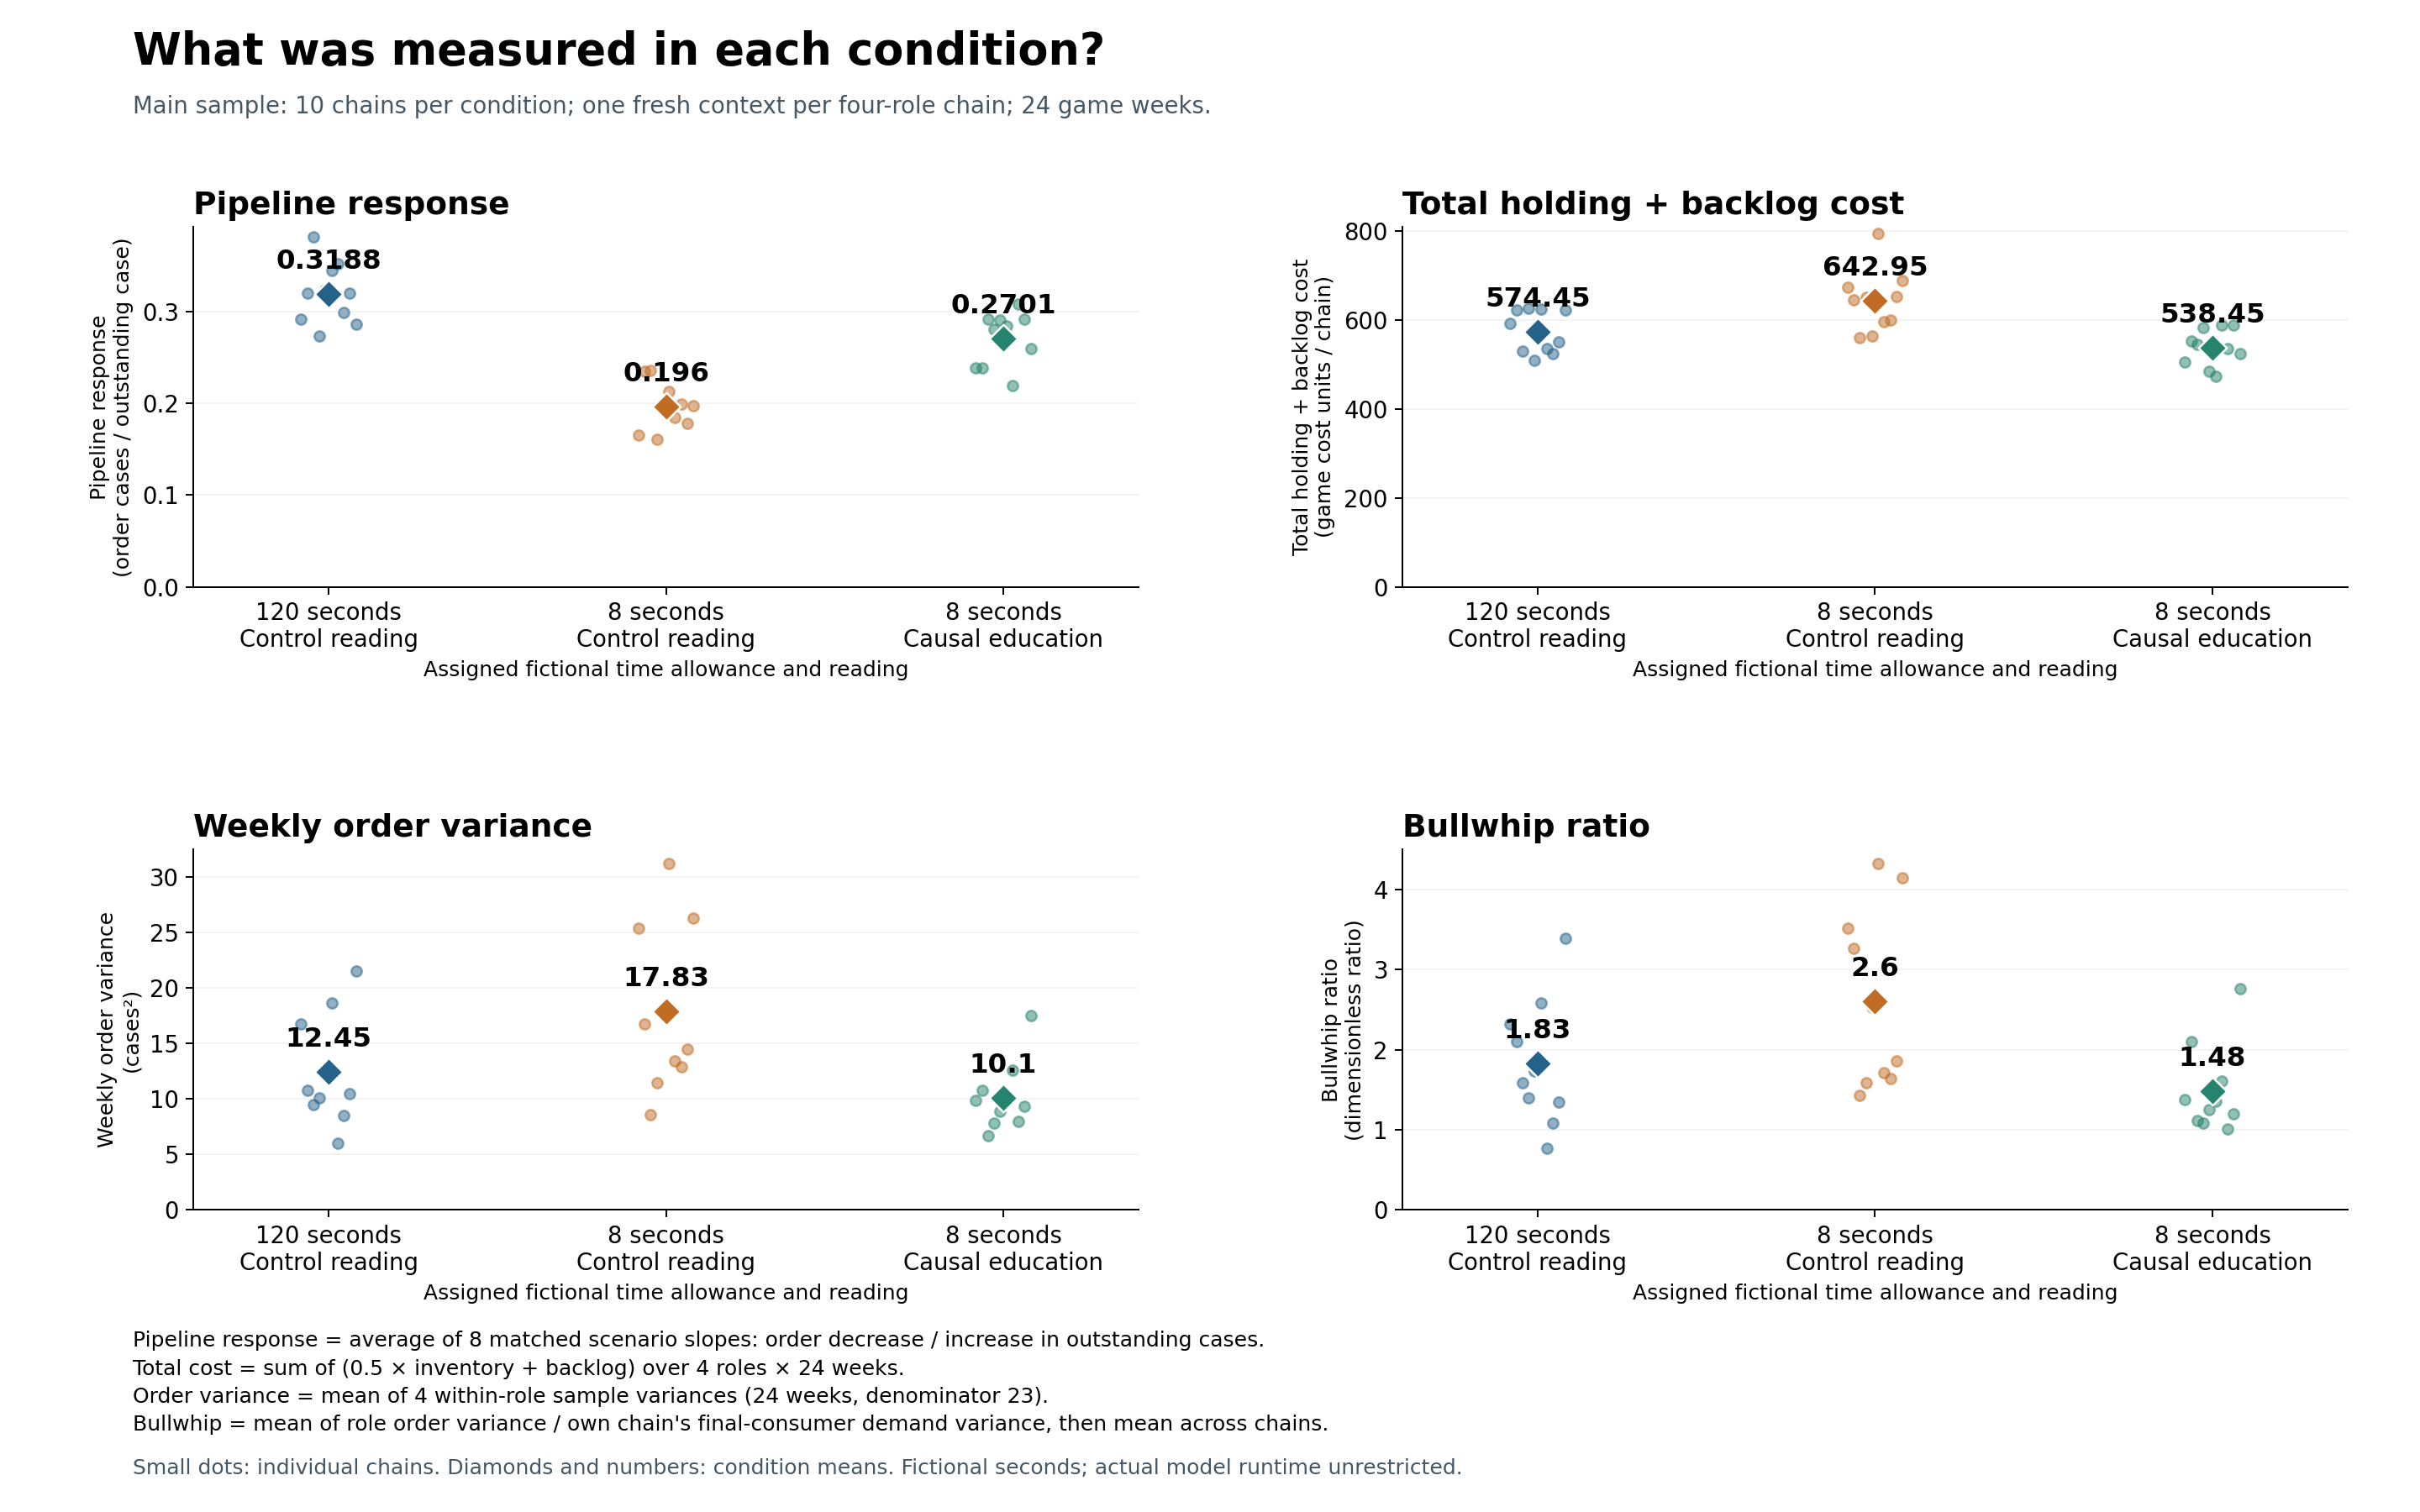

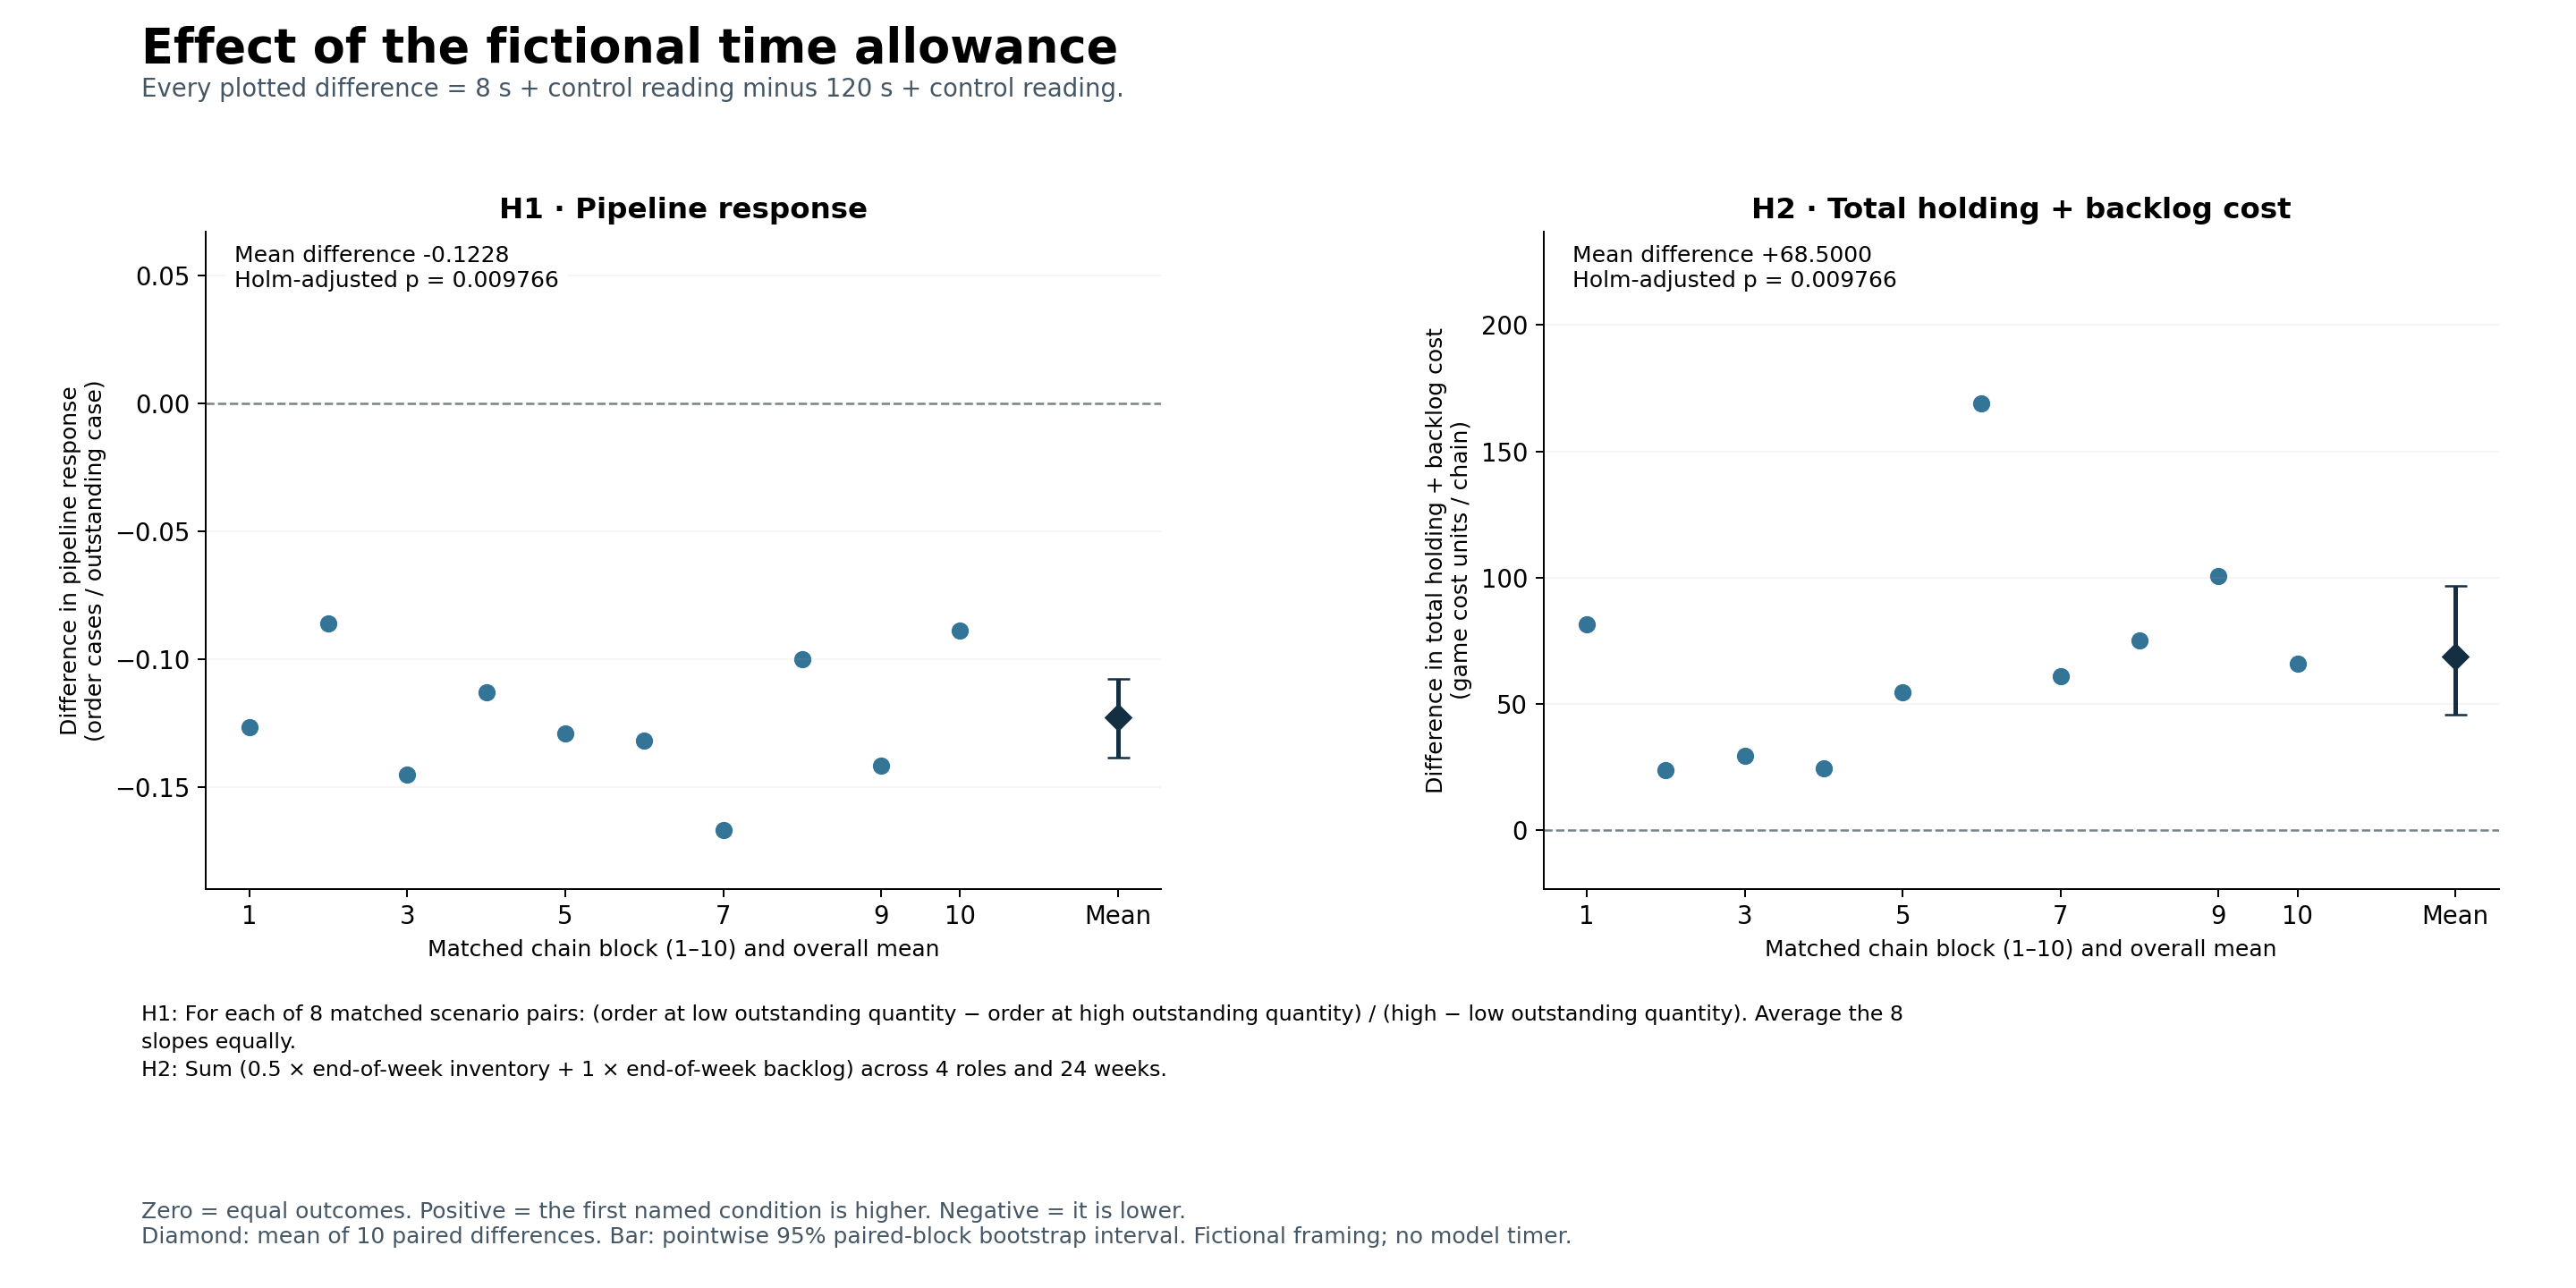

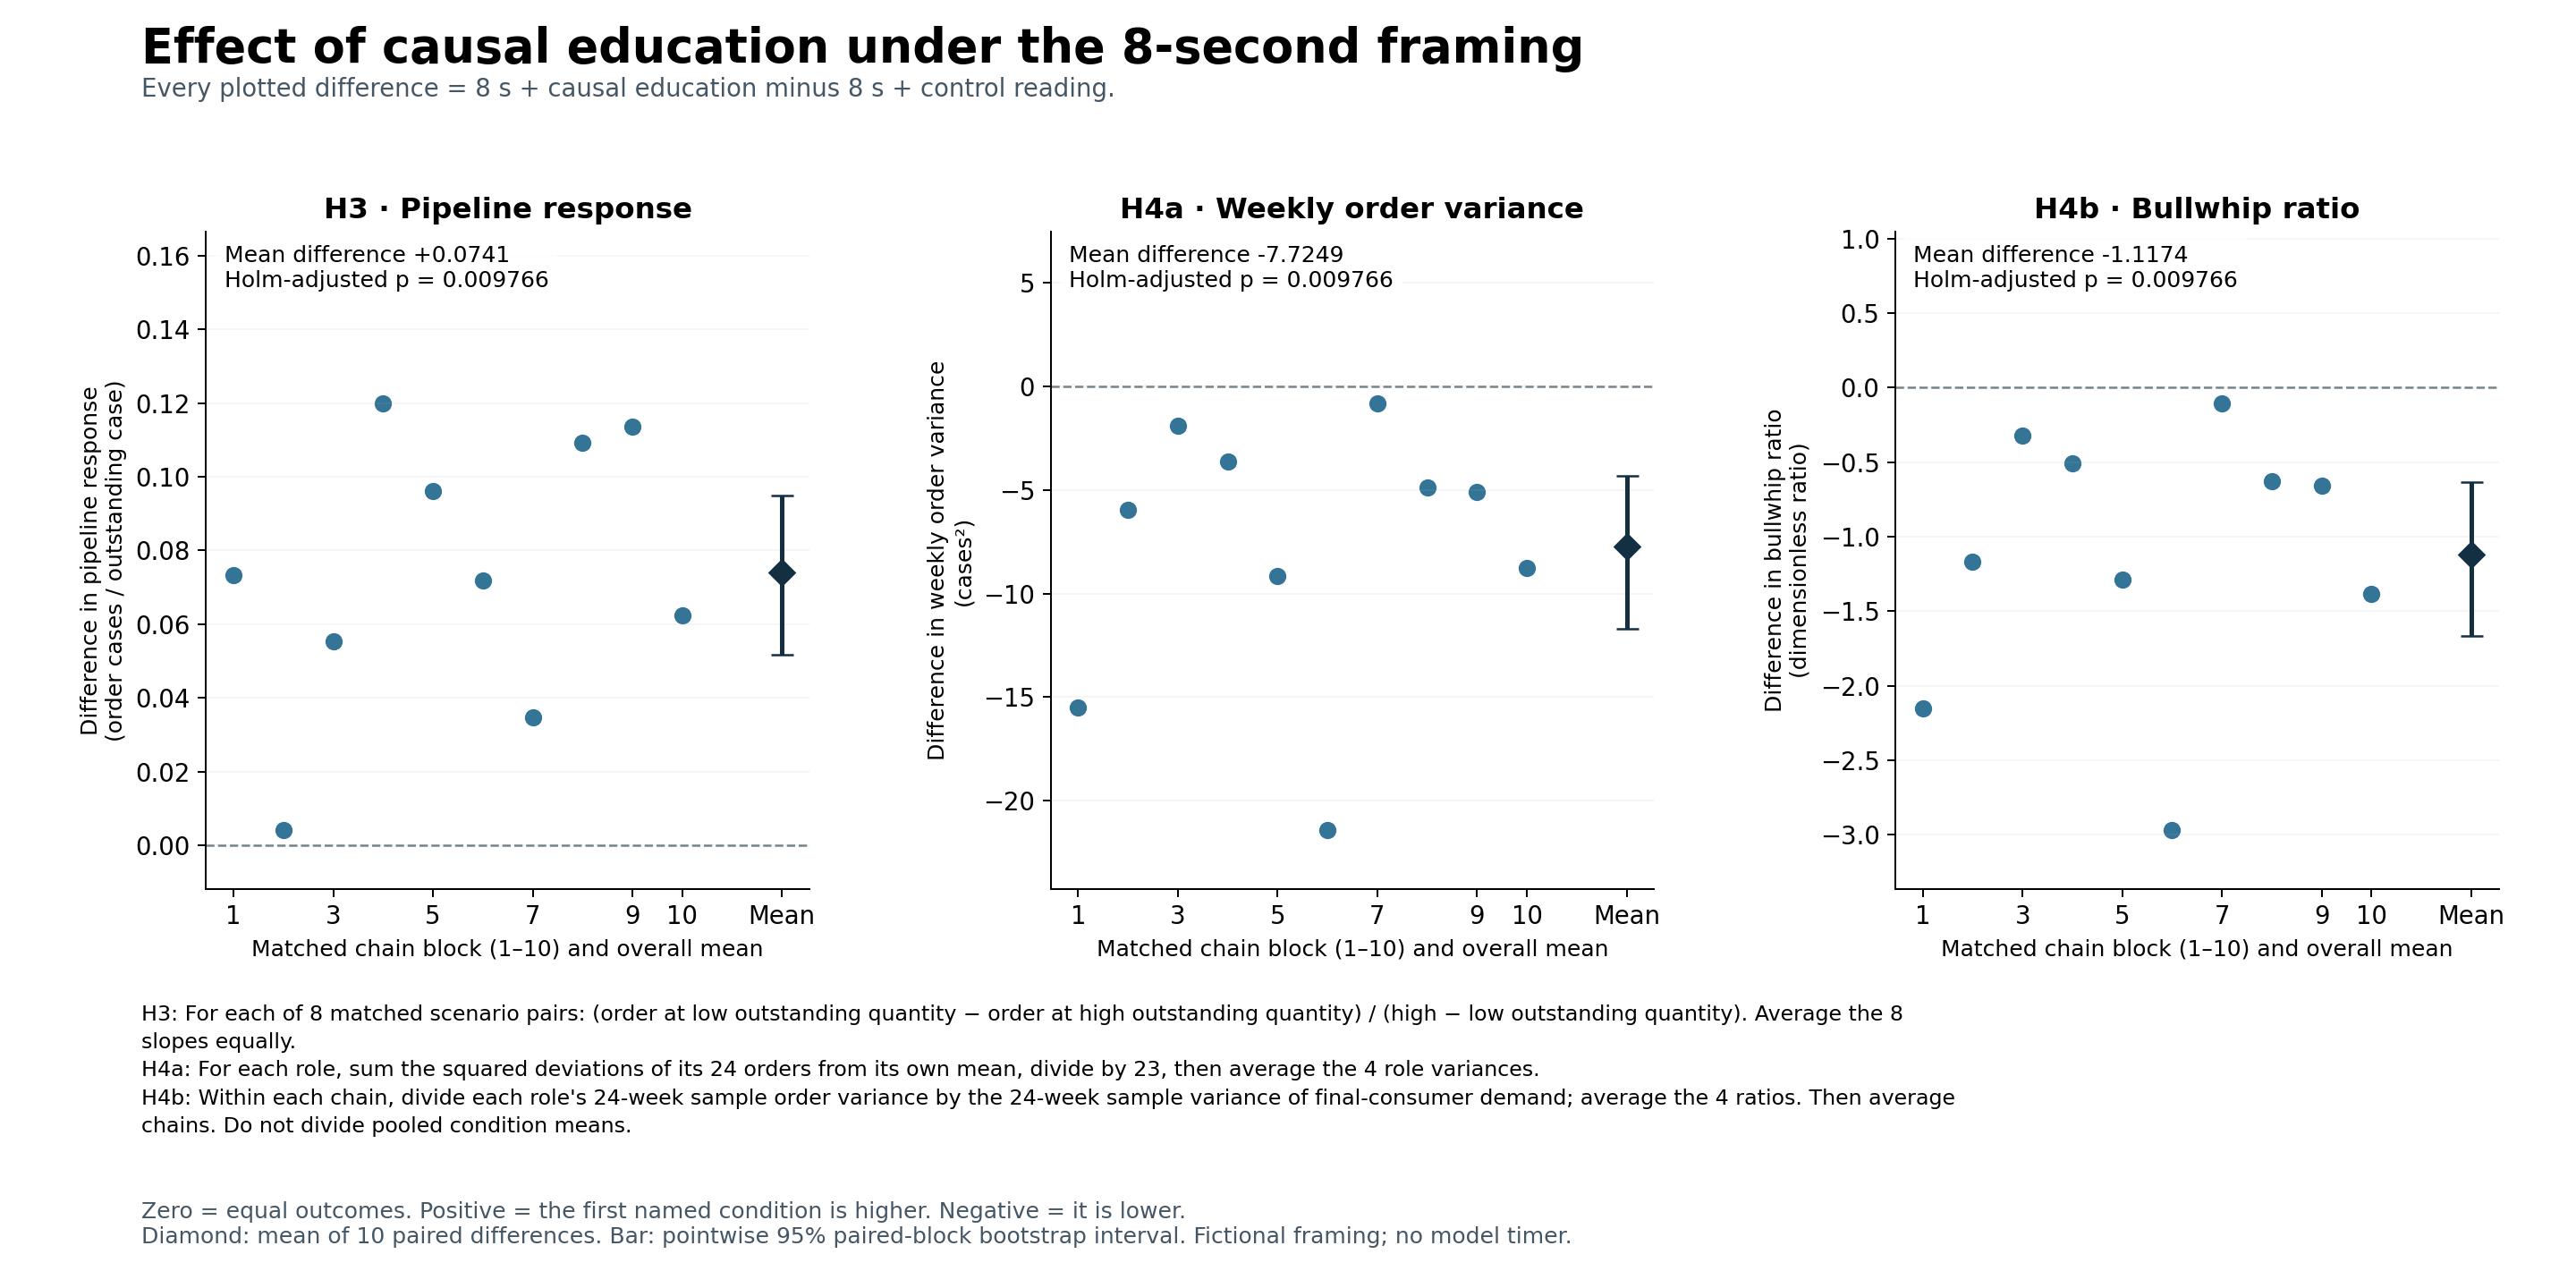

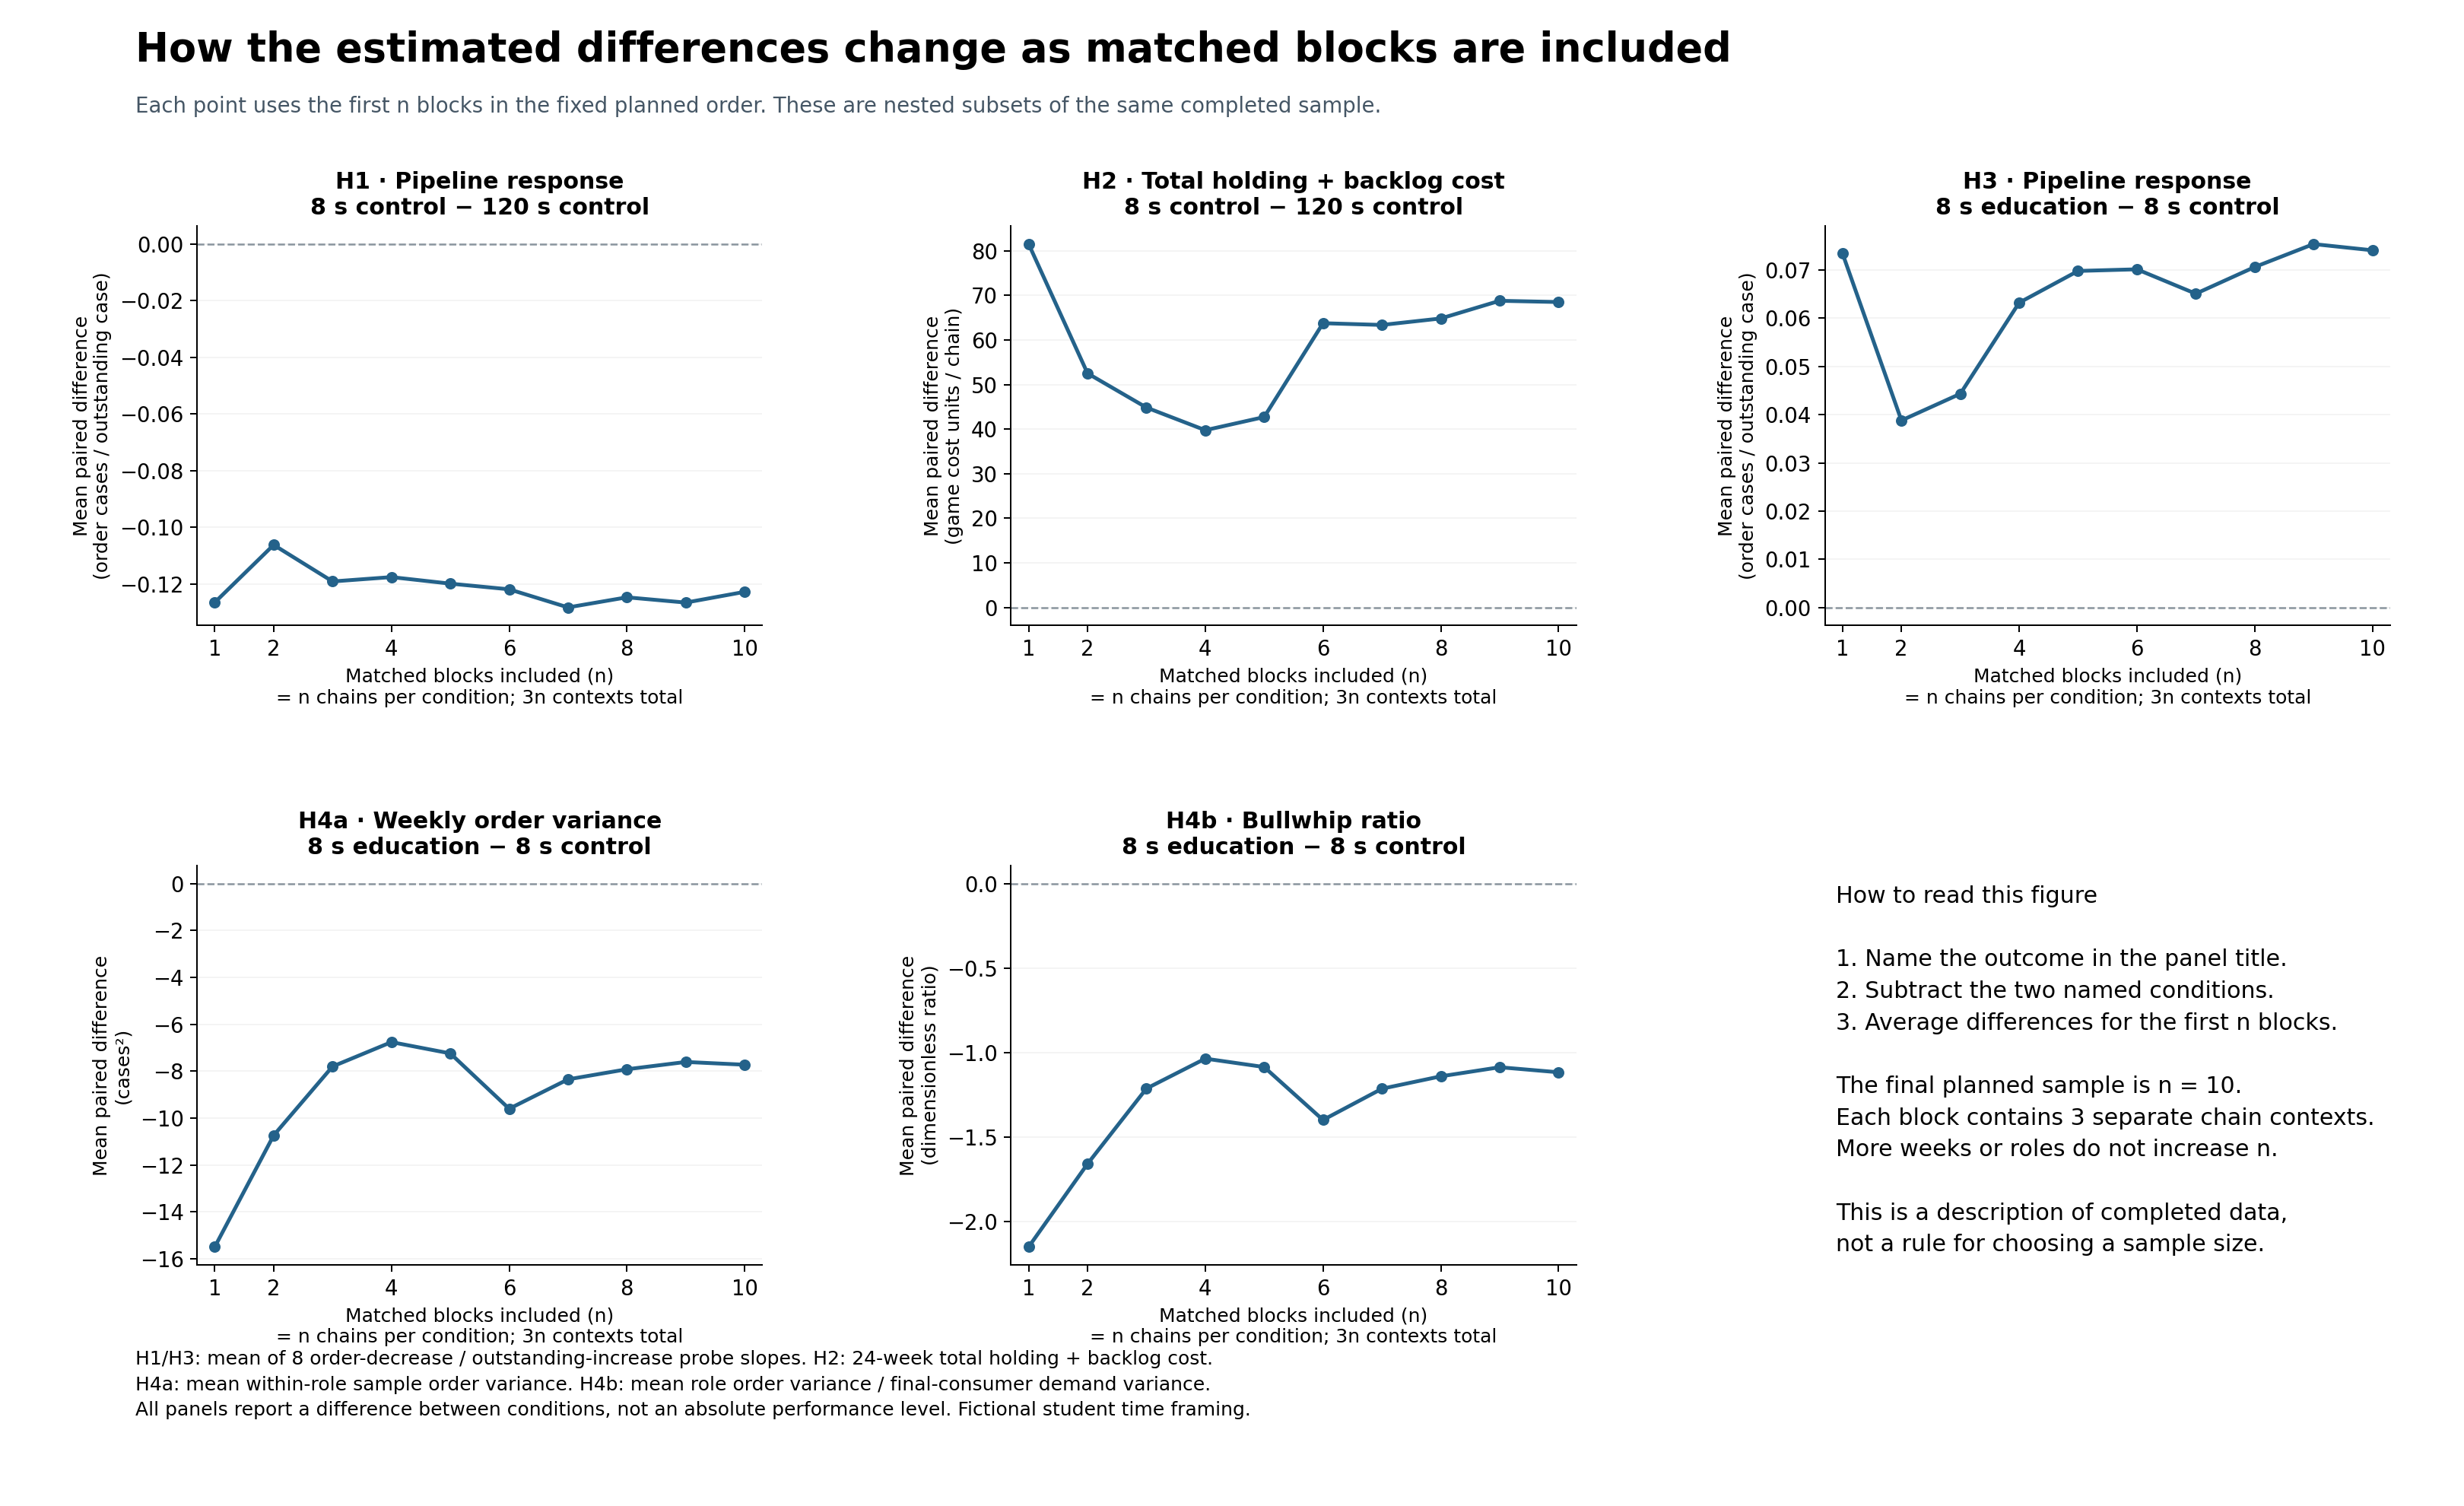

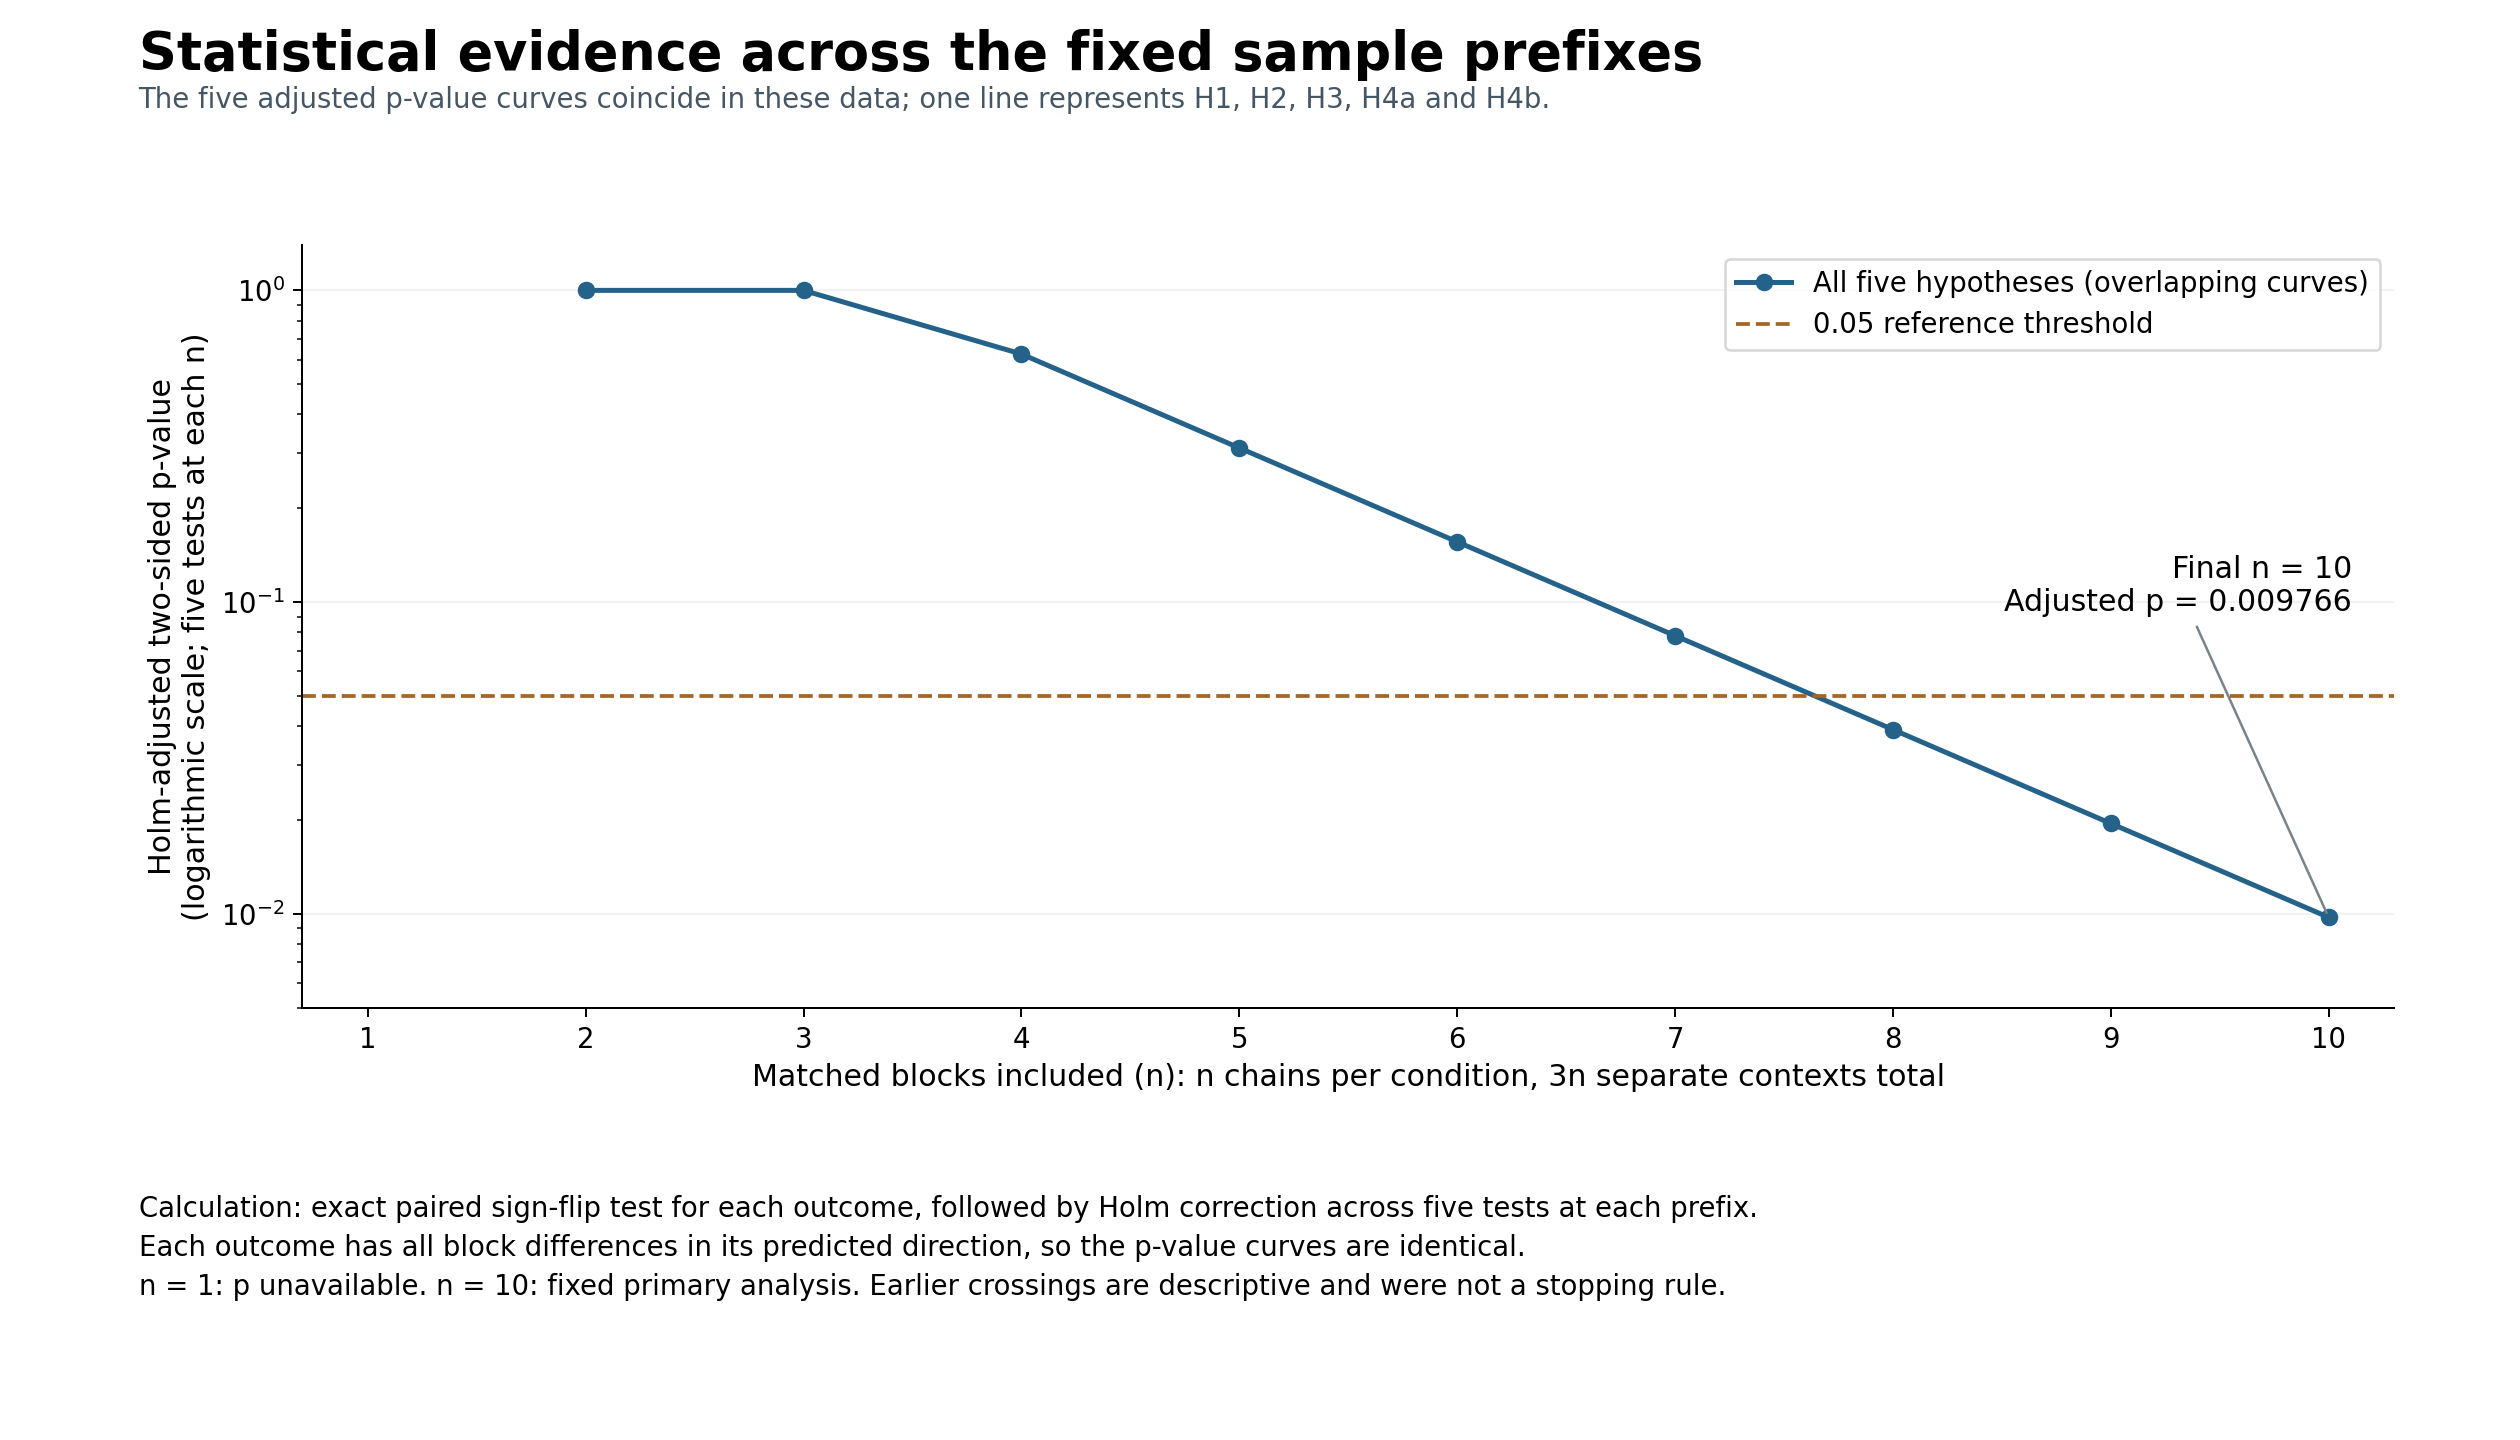

In [4]:
for name in ("01_CONDITION_VALUES", "02_PRESSURE_COMPARISON", "03_EDUCATION_COMPARISON", "04_SAMPLE_SIZE_EFFECTS", "05_SAMPLE_SIZE_PVALUES"):
    display(Image(filename=str(BASE / "figures" / (name + ".png")), width=1200))

## Optional: reproduce the current publication

Leave `REBUILD = False` to use the existing report. To regenerate it from the closed records, set it to `True`. The report, plots and tables share one publisher. Install the repository's `requirements.txt` in this kernel's Python environment if dependencies are missing. This does not collect any responses.

In [5]:
REBUILD = False
if REBUILD:
    import subprocess
    subprocess.run([sys.executable, str(ROOT / "scripts/report_exp14_framing.py")], cwd=ROOT, check=True)
else:
    print("Using the completed publication. No model calls or file changes.")

Using the completed publication. No model calls or file changes.
